In [1]:
import pandas as pd

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

In [3]:
df = pd.read_csv("../data/processed/clean_sales.csv")

print("Shape:", df.shape)
print(df.head())

Shape: (9994, 27)
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156  2016-11-08  2016-11-11    Second Class    CG-12520   
1       2  CA-2016-152156  2016-11-08  2016-11-11    Second Class    CG-12520   
2       3  CA-2016-138688  2016-06-12         NaN    Second Class    DV-13045   
3       4  US-2015-108966  2015-10-11         NaN  Standard Class    SO-20335   
4       5  US-2015-108966  2015-10-11         NaN  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...     Sales  \
0      Claire Gute   Consumer  United States        Henderson  ...  261.9600   
1      Claire Gute   Consumer  United States        Henderson  ...  731.9400   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   14.6200   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...  957.5775   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   22.3680   

   Quantity Di

In [5]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
print(df["Order Date"].min())
print(df["Order Date"].max())

2014-01-03 00:00:00
2017-12-11 00:00:00


In [6]:
print("Minimum date:", df["Order Date"].min())
print("Maximum date:", df["Order Date"].max())

Minimum date: 2014-01-03 00:00:00
Maximum date: 2017-12-11 00:00:00


In [7]:
max_date = df["Order Date"].max()

cutoff_date = max_date - pd.Timedelta(days=90)

print("Maximum Date:", max_date)
print("Cutoff Date:", cutoff_date)

Maximum Date: 2017-12-11 00:00:00
Cutoff Date: 2017-09-12 00:00:00


In [8]:
historical_df = df[
    df["Order Date"] <= cutoff_date
].copy()

In [9]:
future_df = df[
    df["Order Date"] > cutoff_date
].copy()

In [10]:
print("Historical:", historical_df.shape)
print("Future:", future_df.shape)

Historical: (3481, 27)
Future: (561, 27)


In [13]:
customer_features = historical_df.groupby("Customer Name").agg(
    Last_Order_Date=("Order Date", "max"),
    Frequency=("Order ID", "nunique"),
    Monetary=("Sales", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Discount=("Discount", "mean"),
    First_Order_Date=("Order Date", "min")
).reset_index()
print(customer_features.head())

        Customer Name Last_Order_Date  Frequency  Monetary  Total_Quantity  \
0       Aaron Bergman      2016-11-10          2   873.532              11   
1      Aaron Smayling      2017-09-04          3  2304.558              30   
2     Adam Bellavance      2017-05-07          2  4518.676              13   
3  Adam Shillingsburg      2017-04-01          4  1252.316              40   
4       Adrian Barton      2017-08-03          4  1299.154              33   

   Average_Discount First_Order_Date  
0          0.040000       2014-03-07  
1          0.533333       2017-01-02  
2          0.066667       2016-09-01  
3          0.145455       2015-11-09  
4          0.311111       2015-11-07  


In [14]:
customer_features["Recency"] = (
    cutoff_date -
    customer_features["Last_Order_Date"]
).dt.days

In [15]:
customer_features["Average_Order_Value"] = (
    customer_features["Monetary"] /
    customer_features["Frequency"]
)

In [17]:
customer_features["Customer_Lifespan"] = (
    customer_features["Last_Order_Date"] -
    customer_features["First_Order_Date"]
).dt.days
print(customer_features.head())

        Customer Name Last_Order_Date  Frequency  Monetary  Total_Quantity  \
0       Aaron Bergman      2016-11-10          2   873.532              11   
1      Aaron Smayling      2017-09-04          3  2304.558              30   
2     Adam Bellavance      2017-05-07          2  4518.676              13   
3  Adam Shillingsburg      2017-04-01          4  1252.316              40   
4       Adrian Barton      2017-08-03          4  1299.154              33   

   Average_Discount First_Order_Date  Recency  Average_Order_Value  \
0          0.040000       2014-03-07      306             436.7660   
1          0.533333       2017-01-02        8             768.1860   
2          0.066667       2016-09-01      128            2259.3380   
3          0.145455       2015-11-09      164             313.0790   
4          0.311111       2015-11-07       40             324.7885   

   Customer_Lifespan  
0                979  
1                245  
2                248  
3                5

Create the target variable

In [18]:
future_customers = set(
    future_df["Customer Name"].unique()
)

In [21]:
customer_features["Returned"] = (
    customer_features["Customer Name"]
    .isin(future_customers)
    .astype(int)
)
print(
    customer_features["Returned"].value_counts()
)
print(
    customer_features["Returned"]
    .value_counts(normalize=True) * 100
)

Returned
0    499
1    210
Name: count, dtype: int64
Returned
0    70.380818
1    29.619182
Name: proportion, dtype: float64


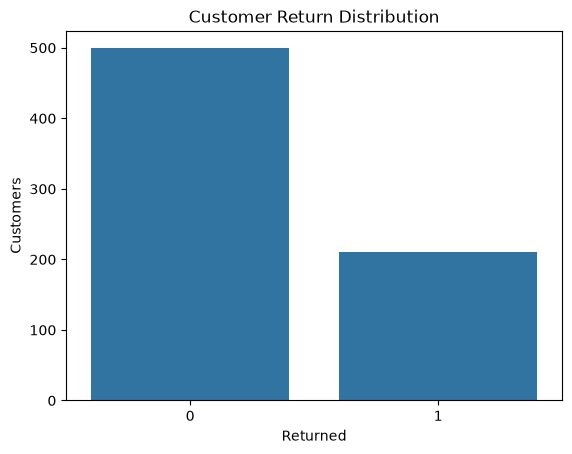

In [22]:
sns.countplot(
    data=customer_features,
    x="Returned"
)

plt.title("Customer Return Distribution")
plt.xlabel("Returned")
plt.ylabel("Customers")

plt.show()

In [23]:
features = [
    "Recency",
    "Frequency",
    "Monetary",
    "Total_Quantity",
    "Average_Discount",
    "Average_Order_Value",
    "Customer_Lifespan"
]

In [25]:
X = customer_features[features]

y = customer_features["Returned"]

print(X.head())
print(y.head())

   Recency  Frequency  Monetary  Total_Quantity  Average_Discount  \
0      306          2   873.532              11          0.040000   
1        8          3  2304.558              30          0.533333   
2      128          2  4518.676              13          0.066667   
3      164          4  1252.316              40          0.145455   
4       40          4  1299.154              33          0.311111   

   Average_Order_Value  Customer_Lifespan  
0             436.7660                979  
1             768.1860                245  
2            2259.3380                248  
3             313.0790                509  
4             324.7885                635  
0    0
1    1
2    1
3    1
4    0
Name: Returned, dtype: int64


In [26]:
print(X.isnull().sum())

Recency                0
Frequency              0
Monetary               0
Total_Quantity         0
Average_Discount       0
Average_Order_Value    0
Customer_Lifespan      0
dtype: int64


Train/Test Split

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Logistic Regression mode

In [28]:
logistic_model = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [29]:
logistic_model.fit(
    X_train,
    y_train
)
logistic_predictions = logistic_model.predict(X_test)

logistic_probabilities = logistic_model.predict_proba(
    X_test
)[:, 1]

Evaluate Logistic Regression

In [30]:
logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

logistic_precision = precision_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

logistic_recall = recall_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

logistic_f1 = f1_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

logistic_auc = roc_auc_score(
    y_test,
    logistic_probabilities
)
print("Logistic Regression")
print("=" * 40)

print(f"Accuracy  : {logistic_accuracy:.4f}")
print(f"Precision : {logistic_precision:.4f}")
print(f"Recall    : {logistic_recall:.4f}")
print(f"F1 Score  : {logistic_f1:.4f}")
print(f"ROC-AUC   : {logistic_auc:.4f}")

Logistic Regression
Accuracy  : 0.6972
Precision : 0.0000
Recall    : 0.0000
F1 Score  : 0.0000
ROC-AUC   : 0.4564


In [31]:
rf_model = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=10,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

In [32]:
rf_model.fit(
    X_train,
    y_train
)
rf_predictions = rf_model.predict(X_test)

rf_probabilities = rf_model.predict_proba(
    X_test
)[:, 1]

Evaluate Random Forest

In [33]:
rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

rf_precision = precision_score(
    y_test,
    rf_predictions,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_predictions,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_predictions,
    zero_division=0
)

rf_auc = roc_auc_score(
    y_test,
    rf_probabilities
)

In [34]:
print("Random Forest")
print("=" * 40)

print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1 Score  : {rf_f1:.4f}")
print(f"ROC-AUC   : {rf_auc:.4f}")

Random Forest
Accuracy  : 0.5775
Precision : 0.3200
Recall    : 0.3810
F1 Score  : 0.3478
ROC-AUC   : 0.4738


In [36]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        rf_accuracy
    ],
    "Precision": [
        logistic_precision,
        rf_precision
    ],
    "Recall": [
        logistic_recall,
        rf_recall
    ],
    "F1": [
        logistic_f1,
        rf_f1
    ],
    "ROC_AUC": [
        logistic_auc,
        rf_auc
    ]
})

print(
    results.round(4)
)

                 Model  Accuracy  Precision  Recall      F1  ROC_AUC
0  Logistic Regression    0.6972       0.00   0.000  0.0000   0.4564
1        Random Forest    0.5775       0.32   0.381  0.3478   0.4738


Confusion Matrix

In [37]:
cm = confusion_matrix(
    y_test,
    rf_predictions
)

print(cm)

[[66 34]
 [26 16]]


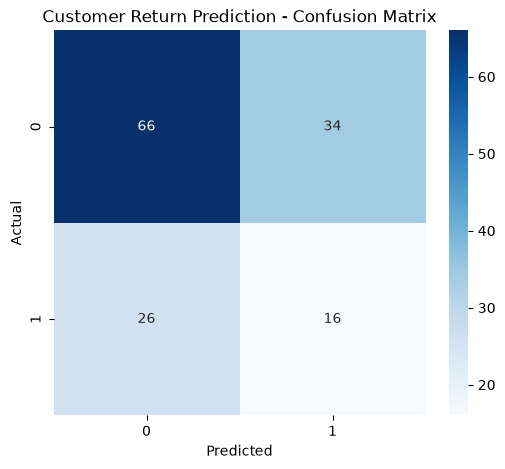

In [38]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Customer Return Prediction - Confusion Matrix")

plt.show()

In [39]:
print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=[
            "Did Not Return",
            "Returned"
        ],
        zero_division=0
    )
)

                precision    recall  f1-score   support

Did Not Return       0.72      0.66      0.69       100
      Returned       0.32      0.38      0.35        42

      accuracy                           0.58       142
     macro avg       0.52      0.52      0.52       142
  weighted avg       0.60      0.58      0.59       142



In [40]:
rf_estimator = rf_model.named_steps["model"]
importance = rf_estimator.feature_importances_

In [41]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": importance
}).sort_values(
    "Importance",
    ascending=False
)

print(feature_importance)

               Feature  Importance
5  Average_Order_Value    0.181610
2             Monetary    0.170810
0              Recency    0.169361
3       Total_Quantity    0.146339
4     Average_Discount    0.143240
6    Customer_Lifespan    0.141547
1            Frequency    0.047092


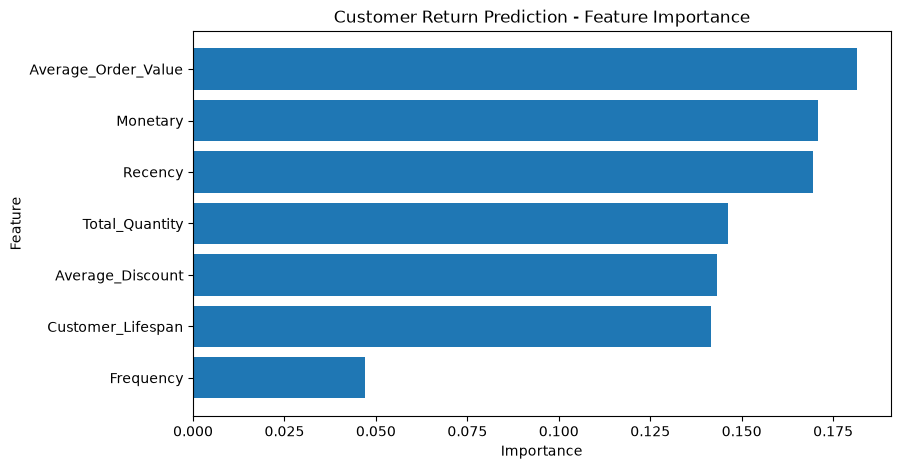

In [42]:
plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Customer Return Prediction - Feature Importance")

plt.gca().invert_yaxis()

plt.show()

In [43]:
import os
os.makedirs("../data/ml", exist_ok=True)

customer_features.to_csv(
    "../data/ml/customer_return_dataset.csv", index=False
)

In [44]:
os.makedirs("../models", exist_ok=True)

joblib.dump(
    rf_model,
    "../models/customer_return_model.pkl"
)

['../models/customer_return_model.pkl']

In [45]:
results.to_csv(
    "../reports/customer_return_model_results.csv",
    index=False
)